# code_012 · Random variables and conditional distributions

**Book:** Chapter 3, section 3.1. **Purpose:** an independent probability/statistics laboratory with synthetic populations and declared measurement models. No numerical result is evidence of structural safety, an empirical causal effect or production reliability.

Use the repository [quickstart](../README.md), select the [pinned environment](../requirements-lock.txt), restart and run every cell. Reference target: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, CPU only on macOS ARM64. All inputs, generators and helper definitions are here. Normal runs require no network, data files, API keys, GPU or private imports. Allow a minute for execution and 30–60 minutes for interpretation/exercises. Actual versions and time appear below and in [run evidence](../CHAPTER_03_EXECUTION.md).

Read predictions before output. Sampling assumptions, priors, numerical simulation budgets and decision margins have different roles; they are not all model hyperparameters. These are scoped concept laboratories, not full estimator-constructor guides. The [traceability guide](../CHAPTER_03_GUIDE.md) maps mechanisms and exercises, and the [stable registry](../CODE_EXAMPLES.md#code_012) preserves this ID. Synthetic algebra/population checks need no learned train/test split; any fitted prediction experiment below states its calibration and assessment boundaries.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import stats,special
from IPython.display import display
START=time.perf_counter();SEED=312
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 312


<a id="joint-table"></a>
## A fully specified invented population

The event F is one if a member exceeds a declared inspection criterion within one year. It is not a collapse event. Material and high/low load define four strata. We enumerate exact synthetic counts, so the table is a descriptive finite-population calculation. Estimating an unknown wider population adds the sampling questions in section 3.2.

**Predict:** does the rate among high-load members use all members, high-load members or exceeded-criterion members as denominator? Why can switching denominators reverse the question?


In [2]:
cohort=pd.DataFrame({'material':['A','A','B','B'],'high_load':[False,True,False,True],
'n':[720,80,80,120],'exceedances':[36,16,8,36]})
assert (cohort.exceedances<=cohort.n).all() and cohort.n.sum()==1000
cohort['rate']=cohort.exceedances/cohort.n
joint=[]
for row in cohort.itertuples():
 for outcome,count in [(0,row.n-row.exceedances),(1,row.exceedances)]:
  joint.append([row.material,row.high_load,outcome,count,count/1000])
joint=pd.DataFrame(joint,columns=['material','high_load','F','count','probability'])
assert np.isclose(joint.probability.sum(),1)
display(cohort);display(joint)


,material,high_load,n,exceedances,rate
0,A,False,720,36,0.05
1,A,True,80,16,0.20
2,B,False,80,8,0.10
3,B,True,120,36,0.30


,material,high_load,F,count,probability
0,A,False,0,684,0.684
1,A,False,1,36,0.036
2,A,True,0,64,0.064
3,A,True,1,16,0.016
4,B,False,0,72,0.072
5,B,False,1,8,0.008
6,B,True,0,84,0.084
7,B,True,1,36,0.036


<a id="conditionals"></a>
## Same numerator, different questions

P(F=1 | H=1)=52/200; P(H=1 | F=1)=52/96. Independence would require P(F,H)=P(F)*P(H). The table violates that equality; it does not establish what would happen if load were intervened on. A feature conditioning a forecast must also be available at prediction time.

**Predict:** can the overall rate be recovered as a weighted average of the two load-specific rates? What fraction of high-load members use material B?


{'P(F)': np.float64(0.096), 'P(F|H)': np.float64(0.26), 'P(H|F)': np.float64(0.5416666666666666), 'P(F,H)': np.float64(0.052), 'P(F)P(H)': np.float64(0.019200000000000002)}


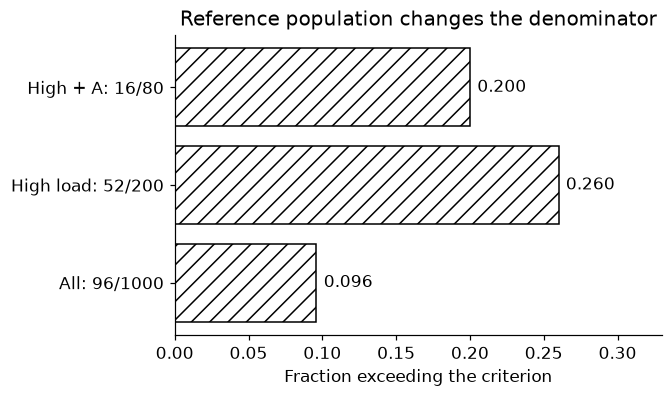

In [3]:
heavy=cohort.high_load;fail=cohort.exceedances.sum();N=cohort.n.sum()
heavy_n=cohort.loc[heavy,'n'].sum();heavy_fail=cohort.loc[heavy,'exceedances'].sum()
pF=fail/N;pH=heavy_n/N;pFH=heavy_fail/N
conditional=heavy_fail/heavy_n;reverse=heavy_fail/fail
low=(fail-heavy_fail)/(N-heavy_n)
assert np.isclose(pF,.096) and np.isclose(conditional,.26)
assert np.isclose(reverse,52/96) and not np.isclose(pFH,pF*pH)
assert np.isclose(conditional*pH+low*(1-pH),pF)
print({'P(F)':pF,'P(F|H)':conditional,'P(H|F)':reverse,'P(F,H)':pFH,'P(F)P(H)':pF*pH})
fig,ax=plt.subplots(figsize=(6,3.5));labels=['All: 96/1000','High load: 52/200','High + A: 16/80']
values=[pF,conditional,.2];bars=ax.barh(labels,values,color='white',edgecolor='black',hatch='//')
ax.set(xlabel='Fraction exceeding the criterion',xlim=(0,.33),title='Reference population changes the denominator')
for bar,value in zip(bars,values):ax.text(value+.005,bar.get_y()+bar.get_height()/2,f'{value:.3f}',va='center')
plt.show();RESULTS['overall_rate']=float(pF);RESULTS['high_load_rate']=float(conditional);RESULTS['reverse_conditional']=float(reverse)


<a id="mixtures"></a>
## Mixture shift without changing conditional rates

Hold P(F|H) and P(F|not H) fixed, then change only the fraction of high-load members. This is a transparent population-weight scenario, not evidence that those conditional rates transfer to another population. There is no causal effect estimate in this exercise. Material-specific high-load rates also differ, so changing material mix may require finer stratification.

**Predict:** if 60% of a new population is high load, will its overall rate still be .096? What assumption makes the following weighted calculation usable?


In [4]:
weights=np.array([.2,.4,.6,.8]);mixture_rates=conditional*weights+low*(1-weights)
assert np.isclose(mixture_rates[0],pF) and np.isclose(mixture_rates[2],.178)
display(pd.DataFrame({'fraction_high_load':weights,'scenario_rate':mixture_rates}))
bernoulli=rng.binomial(1,conditional,100000)
assert abs(bernoulli.mean()-conditional)<.005
assert abs(bernoulli.var()-conditional*(1-conditional))<.005
RESULTS['rate_if_60pct_high_load']=float(mixture_rates[2]);RESULTS['bernoulli_expected_variance']=float(conditional*(1-conditional))


,fraction_high_load,scenario_rate
0,0.2,0.096
1,0.4,0.137
2,0.6,0.178
3,0.8,0.219


<a id="continuous"></a>
## Density height is not probability

A separate illustrative deflection Y follows Normal(mean=1 mm, sd=.2 mm). Its density has units 1/mm and its peak exceeds one. A probability is an integral; the CDF difference over [0.9,1.1] mm is between zero and one. This distribution is not secretly the generator of the earlier binary table. Expectation is a distribution average; it need not be an individual observed value. Under squared error it is the best point summary, while absolute error favors a median.

**Predict:** how does density height change when deflection is expressed in metres? Does the probability over the same physical interval change?


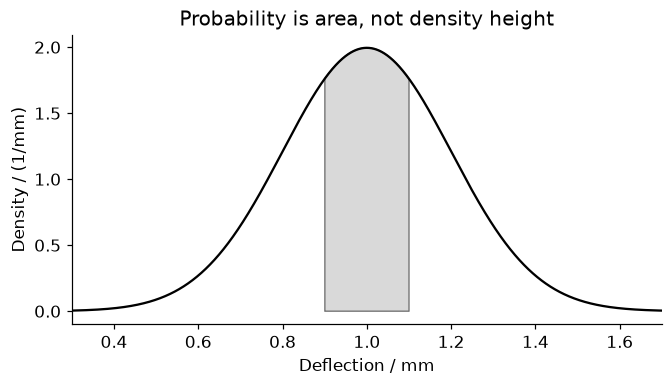

Peak density: 1.9947114020071635 probability in [0.9,1.1] mm: 0.3829249225480263


In [5]:
mu,sigma=1.,.2;grid=np.linspace(mu-8*sigma,mu+8*sigma,8001)
density=stats.norm.pdf(grid,mu,sigma);area=np.trapezoid(density,grid)
probability=stats.norm.cdf(1.1,mu,sigma)-stats.norm.cdf(.9,mu,sigma)
probability_m=stats.norm.cdf(.0011,.001,.0002)-stats.norm.cdf(.0009,.001,.0002)
assert np.isclose(area,1,atol=1e-12) and stats.norm.pdf(mu,mu,sigma)>1
assert np.isclose(probability,probability_m)
fig,ax=plt.subplots(figsize=(6,3.4));ax.plot(grid,density,'k-');mask=(grid>=.9)&(grid<=1.1)
ax.fill_between(grid[mask],density[mask],color='.85',hatch='//',edgecolor='.5')
ax.set(xlim=(.3,1.7),xlabel='Deflection / mm',ylabel='Density / (1/mm)',title='Probability is area, not density height');plt.show()
print('Peak density:',stats.norm.pdf(mu,mu,sigma),'probability in [0.9,1.1] mm:',probability)
RESULTS['normal_interval_probability']=float(probability);RESULTS['density_area']=float(area)


<a id="exercises"></a>
## Exercises and hints

1. Calculate material-specific and material-and-load-specific rates. Reconstruct the overall rate using all four population weights.
2. Reverse another conditional and name its numerator/denominator in words before calculating.
3. Construct two nonindependent variables with zero correlation; for example use a symmetric X and Y=X². Explain why zero linear correlation is insufficient.
4. Convert the normal density from inverse mm to inverse m and verify probability invariance.
5. Give a forecast using only available features, then describe what additional assumptions a load-intervention question requires.

**Hints:** probabilities are dimensionless, densities are not; subgroup counts and conditional rates are different objects. Changing an averaging distribution can change a marginal rate with every stratum rate fixed. Conditioning on a probability-zero continuous point uses a conditional-distribution model, not a literal finite-count ratio.

**Troubleshooting:** do not divide by an empty stratum, round counts before computing ratios, or call a density height a probability. The [SciPy normal reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) documents CDF/PDF conventions. Counts, assumptions and all mathematical checks are explicit above.


In [6]:
summary={'example_id':'code_012','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['joint marginal and conditional probabilities', 'explicit denominators and reverse conditionals', 'independence', 'population mixtures', 'expectation and variance', 'continuous density units'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["joint marginal and conditional probabilities", "explicit denominators and reverse conditionals", "independence", "population mixtures", "expectation and variance", "continuous density units"], "elapsed_seconds": 0.131, "example_id": "code_012", "hardware": "Darwin arm64 CPU", "results": {"bernoulli_expected_variance": 0.19240000000000002, "density_area": 0.9999999999999989, "high_load_rate": 0.26, "normal_interval_probability": 0.3829249225480263, "overall_rate": 0.096, "rate_if_60pct_high_load": 0.178, "reverse_conditional": 0.5416666666666666}, "seed": 312, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
